# Predicción de enfermedad cardíaca: Regresión Logística (baseline)

Primer modelo de la serie. Los otros dos modelos (Random Forest y XGBoost) están en notebooks separados.

**Dataset:** registros de pacientes con 11 variables clínicas y la columna objetivo `HeartDisease`
(1 = tiene enfermedad cardíaca, 0 = no tiene).

| Variable | Descripción |
|---|---|
| Age | Edad |
| Sex | Sexo (M / F) |
| ChestPainType | Tipo de dolor de pecho (ASY, ATA, NAP, TA) |
| RestingBP | Presión arterial sistólica en reposo (mm Hg) |
| Cholesterol | Colesterol (mg/dl). **Un valor 0 indica dato faltante** |
| FastingBS | Glucemia en ayunas > 120 mg/dl (1 / 0) |
| RestingECG | Electrocardiograma en reposo (Normal, ST, LVH) |
| MaxHR | Frecuencia cardíaca máxima |
| ExerciseAngina | Angina inducida por ejercicio (Y / N) |
| Oldpeak | Depresión del segmento ST |
| ST_Slope | Pendiente del segmento ST (Up, Flat, Down) |

La métrica pedida por la consigna es **accuracy**.

## Notas de metodología

- Todo el preprocesamiento (imputación, encoding, escalado) está dentro de un **`Pipeline` de scikit-learn**,
  así que se ajusta solo con los datos de train de cada fold. Ningún dato de test influye en el entrenamiento.
- El umbral de decisión (threshold) se elige con **predicciones de validación cruzada sobre train**,
  no mirando el conjunto de test.
- El conjunto de test se usa una única vez, al final, para la evaluación.

In [1]:
# La búsqueda de regularización usa l1_ratio sin el parámetro penalty, que requiere scikit-learn 1.8 o superior.
# Si esta celda actualiza la librería, Colab puede pedir reiniciar el entorno: reiniciá y ejecutá todo de nuevo.
!pip install -q -U "scikit-learn>=1.8"

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_predict)
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, auc)
from sklearn.linear_model import LogisticRegression

In [3]:
# Descarga de los datos desde Google Drive (compartidos como "Cualquier persona con el enlace")
import os
import gdown

ARCHIVOS = {
"heart_train.csv": "10zgipXXcGiJn0xqGz90JwtVFOgcdl6UO",
}

for nombre, file_id in ARCHIVOS.items():
    if not os.path.exists(nombre):
        gdown.download(id=file_id, output=nombre, quiet=True)

In [4]:
df = pd.read_csv("heart_train.csv")

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

# stratify mantiene la misma proporción de enfermos y sanos en train y en test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10, stratify=y
)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Proporción de enfermos: {y.mean():.2%}")

Train: (587, 11)   Test: (147, 11)
Proporción de enfermos: 55.31%


## Análisis del colesterol faltante

No existe un colesterol de 0 mg/dl: esos valores son datos faltantes.

In [5]:
print(f"Valores nulos (NaN): {df['Cholesterol'].isna().sum()}")
print(f"Valores en 0: {(df['Cholesterol'] == 0).sum()} ({(df['Cholesterol'] == 0).mean():.2%} de los datos)")

Valores nulos (NaN): 0
Valores en 0: 129 (17.57% de los datos)


Un 17,6% faltante es demasiado para descartar filas. En lugar de imputar con el promedio general,
busco qué variables separan mejor los promedios de colesterol (calculados **sin** los ceros, que no son mediciones reales).

In [6]:
colesterol_valido = df[df["Cholesterol"] > 0]

for columna in ["ChestPainType", "RestingECG", "ST_Slope", "ExerciseAngina"]:
    print(colesterol_valido.groupby(columna)["Cholesterol"].agg(["mean", "size"]).round(1), "\n")

                mean  size
ChestPainType             
ASY            252.2   309
ATA            245.7   131
NAP            238.0   129
TA             232.1    36 

             mean  size
RestingECG             
LVH         257.5   136
Normal      244.0   367
ST          241.0   102 

           mean  size
ST_Slope             
Down      246.3    35
Flat      253.2   286
Up        239.9   284 

                 mean  size
ExerciseAngina             
N               242.7   368
Y               252.6   237 



In [7]:
colesterol_valido.groupby(["RestingECG", "ChestPainType"])["Cholesterol"].agg(["mean", "size"]).round(1)

mean  size
RestingECG ChestPainType             
LVH        ASY            260.7    76
           ATA            263.2    18
           NAP            253.7    31
           TA             236.9    11
Normal     ASY            247.8   171
           ATA            244.6    98
           NAP            236.7    80
           TA             238.0    18
ST         ASY            253.7    62
           ATA            232.3    15
           NAP            216.9    18
           TA             209.4     7

Criterio de imputación: se usa el promedio del grupo `(RestingECG, ChestPainType)`.
Algunas combinaciones tienen muy pocos datos y darían promedios poco robustos, así que
**si el grupo tiene menos de 10 datos, se usa el promedio de `RestingECG` solamente**.
Además, se agrega la columna `IsCholesterolMissing` para que el modelo sepa qué valores fueron imputados.

El imputador está implementado como un transformer de scikit-learn: los promedios se calculan en `fit`
(solo con train) y se aplican en `transform`.

In [8]:
class ImputadorColesterol(BaseEstimator, TransformerMixin):
    """Reemplaza Cholesterol == 0 por el promedio del grupo (RestingECG, ChestPainType).

    Si el grupo tiene menos de `min_grupo` datos, usa el promedio por RestingECG;
    si tampoco existe, el promedio general. Los promedios se calculan solo en fit.
    """

    def __init__(self, min_grupo=10, agregar_indicador=True):
        self.min_grupo = min_grupo
        self.agregar_indicador = agregar_indicador

    def fit(self, X, y=None):
        validos = X[X["Cholesterol"] > 0]
        grupos = validos.groupby(["RestingECG", "ChestPainType"])["Cholesterol"].agg(["mean", "size"])
        self.media_grupo_ = grupos.loc[grupos["size"] >= self.min_grupo, "mean"].to_dict()
        self.media_ecg_ = validos.groupby("RestingECG")["Cholesterol"].mean().to_dict()
        self.media_global_ = validos["Cholesterol"].mean()
        return self

    def _imputar(self, fila):
        clave = (fila["RestingECG"], fila["ChestPainType"])
        if clave in self.media_grupo_:
            return self.media_grupo_[clave]
        return self.media_ecg_.get(fila["RestingECG"], self.media_global_)

    def transform(self, X):
        X = X.copy()
        faltante = X["Cholesterol"] == 0
        if self.agregar_indicador:
            X["IsCholesterolMissing"] = faltante.astype(int)
        X["Cholesterol"] = X["Cholesterol"].astype(float)
        if faltante.any():
            X.loc[faltante, "Cholesterol"] = X.loc[faltante].apply(self._imputar, axis=1)
        return X

## Pipeline de preprocesamiento y modelo

- **Numéricas** (`Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`): `StandardScaler`.
  La regresión logística con regularización es sensible a la escala de las variables.
- **Categóricas**: One Hot Encoding con `drop="first"` para evitar columnas redundantes.
- **Binarias** (`FastingBS`, `IsCholesterolMissing`): sin cambios.

In [9]:
NUMERICAS = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
CATEGORICAS = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
BINARIAS = ["FastingBS", "IsCholesterolMissing"]

In [10]:
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAS),
    ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), CATEGORICAS),
    ("bin", "passthrough", BINARIAS),
], verbose_feature_names_out=False)

pipeline = Pipeline([
    ("imputador", ImputadorColesterol()),
    ("preprocesador", preprocesador),
    ("modelo", LogisticRegression(max_iter=5000, random_state=42)),
])

## Búsqueda de hiperparámetros

Desde scikit-learn 1.8 el parámetro `penalty` está deprecado: el tipo de regularización se elige con `l1_ratio`
(`0` = L2, `1` = L1, valores intermedios = elastic net). Cada solver soporta distintos tipos:

- L2: `lbfgs`
- L1: `liblinear` y `saga`
- Elastic net: `saga`

`C` es la inversa de la fuerza de regularización: más grande, menos regularización.
Como son pocas combinaciones, uso `GridSearchCV` y las pruebo todas.

In [11]:
valores_C = [0.01, 0.1, 0.5, 1, 10]

parametros = [
    {"modelo__solver": ["lbfgs"], "modelo__l1_ratio": [0.0], "modelo__C": valores_C},                # L2
    {"modelo__solver": ["liblinear", "saga"], "modelo__l1_ratio": [1.0], "modelo__C": valores_C},    # L1
    {"modelo__solver": ["saga"], "modelo__l1_ratio": [0.1, 0.5, 0.9], "modelo__C": [0.1, 1, 10]},   # Elastic net
]

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

busqueda = GridSearchCV(pipeline, parametros, scoring="accuracy", cv=cv, n_jobs=-1)
busqueda.fit(X_train, y_train)

mejor_modelo = busqueda.best_estimator_
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Mejor accuracy (CV): {busqueda.best_score_:.4f}")

Mejores parámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 0.1, 'modelo__solver': 'saga'}
Mejor accuracy (CV): 0.8620


## Evaluación en test

In [12]:
def evaluar(modelo, X, y, umbral=0.5, titulo=""):
    """Imprime las métricas en test y grafica la matriz de confusión."""
    probas = modelo.predict_proba(X)[:, 1]
    pred = (probas >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

    print(f"{titulo} (umbral = {umbral:.2f})")
    print(f"  Accuracy:      {accuracy_score(y, pred):.4f}")
    print(f"  Sensibilidad:  {tp / (tp + fn):.4f}   (enfermos detectados)")
    print(f"  Especificidad: {tn / (tn + fp):.4f}   (sanos bien clasificados)")
    print(f"  ROC-AUC:       {roc_auc_score(y, probas):.4f}")
    return probas


def graficar_matriz_confusion(y, pred, titulo):
    plt.figure(figsize=(6, 5))
    sns.heatmap(confusion_matrix(y, pred), annot=True, fmt="d", cmap="Blues", vmin=0,
                xticklabels=["Sano", "Enfermo"], yticklabels=["Sano", "Enfermo"])
    plt.title(titulo)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.show()


def graficar_roc(y, probas, titulo):
    fpr, tpr, _ = roc_curve(y, probas)
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Curva ROC (AUC = {auc(fpr, tpr):.4f})")
    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Clasificador aleatorio")
    plt.xlabel("Tasa de falsos positivos (FPR)")
    plt.ylabel("Tasa de verdaderos positivos (TPR)")
    plt.title(titulo)
    plt.legend(loc="lower right")
    plt.show()

Accuracy en train: 0.8620

Test (umbral = 0.50)
  Accuracy:      0.8707
  Sensibilidad:  0.9012   (enfermos detectados)
  Especificidad: 0.8333   (sanos bien clasificados)
  ROC-AUC:       0.9302


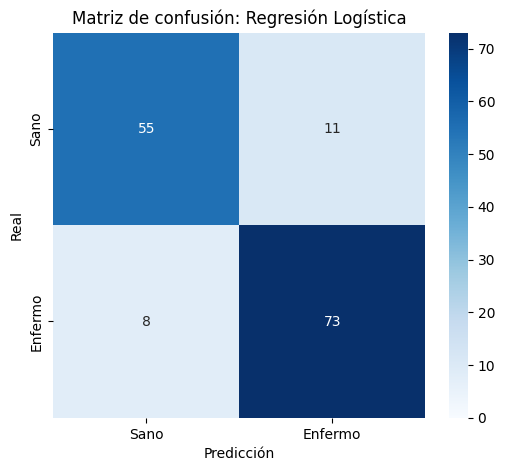

In [13]:
print(f"Accuracy en train: {accuracy_score(y_train, mejor_modelo.predict(X_train)):.4f}\n")
probas_test = evaluar(mejor_modelo, X_test, y_test, titulo="Test")
graficar_matriz_confusion(y_test, mejor_modelo.predict(X_test), "Matriz de confusión: Regresión Logística")

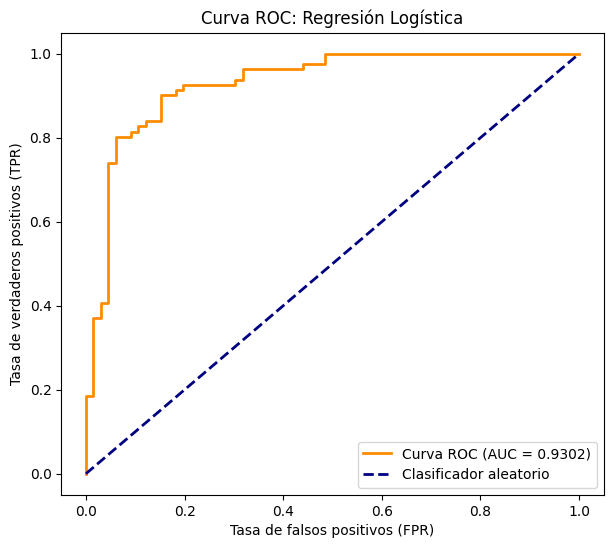

In [14]:
graficar_roc(y_test, probas_test, "Curva ROC: Regresión Logística")

## Coeficientes del modelo

Como las variables numéricas están escaladas, el tamaño de cada coeficiente es comparable.
Un coeficiente positivo aumenta la probabilidad de enfermedad; uno negativo la disminuye.

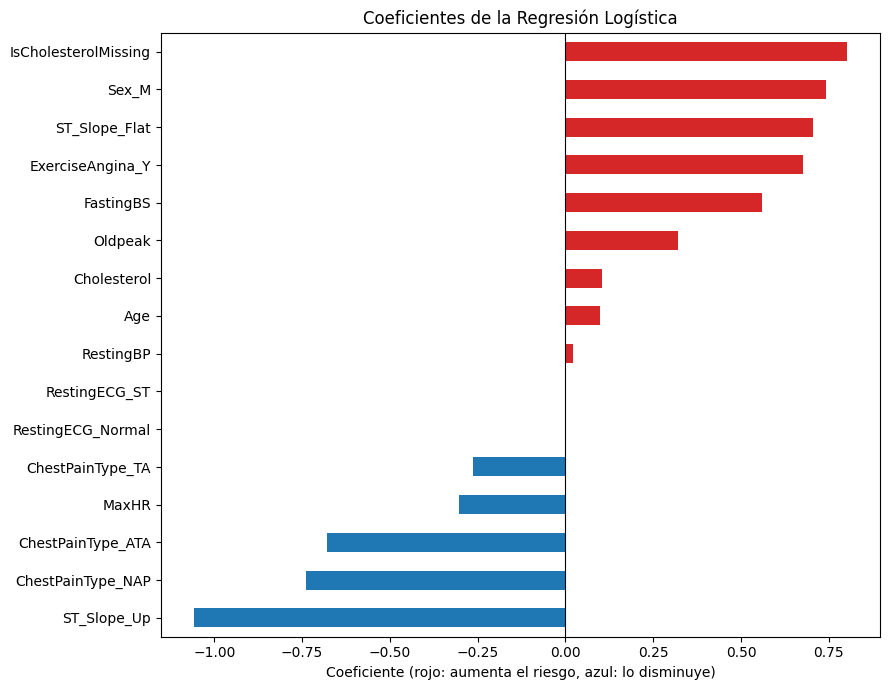

In [15]:
nombres = mejor_modelo.named_steps["preprocesador"].get_feature_names_out()
coeficientes = pd.Series(mejor_modelo.named_steps["modelo"].coef_[0], index=nombres).sort_values()

plt.figure(figsize=(9, 7))
coeficientes.plot(kind="barh", color=np.where(coeficientes > 0, "#d62728", "#1f77b4"))
plt.axvline(0, color="black", lw=0.8)
plt.title("Coeficientes de la Regresión Logística")
plt.xlabel("Coeficiente (rojo: aumenta el riesgo, azul: lo disminuye)")
plt.tight_layout()
plt.show()

## ¿El umbral de decisión impacta en el accuracy?

Busco el umbral que maximiza el accuracy usando **probabilidades de validación cruzada sobre train**.
Elegirlo mirando el test haría que el resultado en test sea optimista.

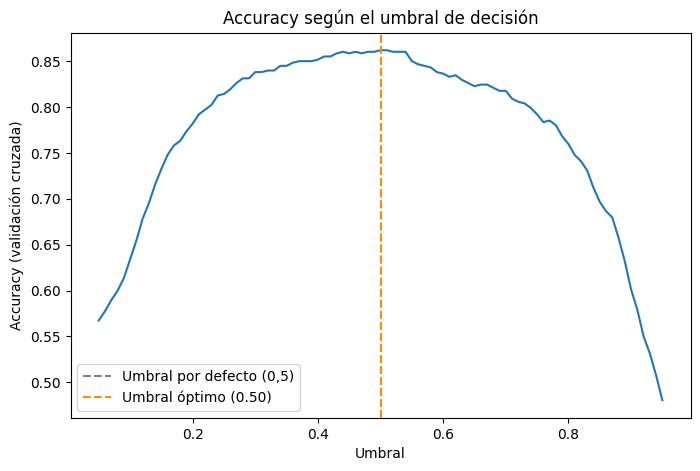

Accuracy CV con umbral 0.50: 0.8620
Accuracy CV con umbral 0.50: 0.8620


In [16]:
probas_cv = cross_val_predict(mejor_modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

umbrales = np.arange(0.05, 0.96, 0.01)
accuracies = [accuracy_score(y_train, (probas_cv >= u).astype(int)) for u in umbrales]
umbral_optimo = umbrales[int(np.argmax(accuracies))]

plt.figure(figsize=(8, 5))
plt.plot(umbrales, accuracies)
plt.axvline(0.5, color="gray", linestyle="--", label="Umbral por defecto (0,5)")
plt.axvline(umbral_optimo, color="darkorange", linestyle="--", label=f"Umbral óptimo ({umbral_optimo:.2f})")
plt.xlabel("Umbral")
plt.ylabel("Accuracy (validación cruzada)")
plt.title("Accuracy según el umbral de decisión")
plt.legend()
plt.show()

print(f"Accuracy CV con umbral 0.50: {accuracy_score(y_train, (probas_cv >= 0.5).astype(int)):.4f}")
print(f"Accuracy CV con umbral {umbral_optimo:.2f}: {max(accuracies):.4f}")

In [17]:
_ = evaluar(mejor_modelo, X_test, y_test, umbral=0.5, titulo="Test")
print()
_ = evaluar(mejor_modelo, X_test, y_test, umbral=umbral_optimo, titulo="Test")

Test (umbral = 0.50)
  Accuracy:      0.8707
  Sensibilidad:  0.9012   (enfermos detectados)
  Especificidad: 0.8333   (sanos bien clasificados)
  ROC-AUC:       0.9302

Test (umbral = 0.50)
  Accuracy:      0.8707
  Sensibilidad:  0.9012   (enfermos detectados)
  Especificidad: 0.8333   (sanos bien clasificados)
  ROC-AUC:       0.9302


Si la mejora con el umbral óptimo es chica, conviene quedarse con 0,5: un umbral muy ajustado
a un dataset de este tamaño puede no generalizar.